# Continuous control: clipped critics and truncated quantiles

TD3 addresses overestimation using twin critics, delayed actor updates and smoothed target actions. TQC retains a distribution of critic returns and discards upper target quantiles. These methods use maintained SB3 implementations; the comparison matches simulator interactions and declares different critic, update, device and wall-time costs.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
torch.set_num_threads(1)


def read(path):
    return json.loads((ROOT / path).read_text())


%matplotlib inline

## Inspect every independent fitted policy

The 100 held-out resets are used only after 12 separate validation resets select the first best checkpoint. Three fitting seeds expose training variation. An episode interval conditions on its fitted policy; it does not estimate uncertainty over training runs.

Fixed-observation actions verify the exported policy. The fresh physics replay is a diagnostic and can vary across CPUs; the comparison plot continues to use the archived independent test scores.


In [2]:
rows = []
for family in ["simulations", "modern"]:
    for path in (ROOT / "results/reference" / family).glob("HalfCheetah*/*/metrics.json"):
        m = json.loads(path.read_text())
        rows.append(
            {
                "method": m["algorithm"],
                "seed": m["seed"],
                "return": m["test"]["mean"],
                "steps": m["actual_steps"],
                "selected": m["selected_step"],
                "updates": m.get("optimizer_updates"),
            }
        )
table = pd.DataFrame(rows).sort_values(["method", "seed"])
assert len(table) == 12
print(table.to_string(index=False))
display(table.groupby("method")["return"].agg(["mean", "std", "min"]))

method  seed      return   steps  selected  updates
   PPO     0 1354.736246 1048576    851968      NaN
   PPO     1 1527.218336 1048576    917504      NaN
   PPO     2 1485.237761 1048576    983040      NaN
   SAC     0 8317.219134 1048576   1048576      NaN
   SAC     1 8223.520872 1048576   1048576      NaN
   SAC     2 7605.357311 1048576   1048576      NaN
   TD3     0 7785.886214 1048576   1048576 259644.0
   TD3     1 8690.610097 1048576    983040 259644.0
   TD3     2 8498.338459 1048576   1048576 259644.0
   TQC     0 8249.876151 1048576   1048576 259644.0
   TQC     1 7811.269863 1048576   1048576 259644.0
   TQC     2 9131.191037 1048576   1048576 259644.0


,mean,std,min
method,,,
PPO,1455.730781,89.947286,1354.736246
SAC,8048.699106,386.792969,7605.357311
TD3,8324.944923,476.634362,7785.886214
TQC,8397.445684,672.220613,7811.269863


Recorded reference returns: [8152.11508299 8287.80246998]
Fresh CPU physics replay returns: [8152.11508299 8287.80246998]


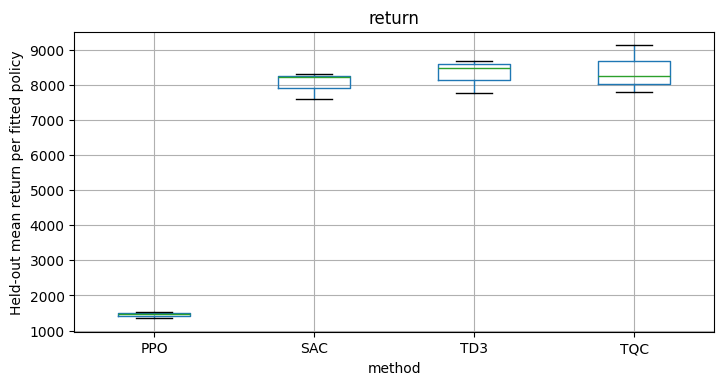

In [3]:
from decision_lab.modern import evaluate
from decision_lab.modern_deployment import load

case = {"env": "HalfCheetah-v5", "algorithm": "TQC", "profile": "official"}
actor = load(ROOT / "assets/modern_actors/HalfCheetah-v5_TQC_official_0.npz")
fresh = evaluate(actor, case, [300000, 300001])
source = np.load(
    ROOT / "assets/source_data/modern/HalfCheetah-v5_TQC_official_0.npz", allow_pickle=False
)
fixed_actions = np.asarray([actor.predict(obs)[0] for obs in source["first_observations"]])
np.testing.assert_allclose(fixed_actions, source["first_actions"], rtol=2e-6, atol=5e-6)
np.testing.assert_array_equal(fresh["first_observations"][0], source["first_observations"][0])
for key in ["lengths", "terminated", "truncated"]:
    np.testing.assert_array_equal(fresh[key], source[key][:2])
assert np.isfinite(fresh["returns"]).all()
print("Recorded reference returns:", source["returns"][:2])
print("Fresh CPU physics replay returns:", fresh["returns"])
fig, ax = plt.subplots(figsize=(8, 4))
table.boxplot(column="return", by="method", ax=ax)
ax.set_ylabel("Held-out mean return per fitted policy")
fig.suptitle("")
plt.show()

## Interpretation

Three fits are a small training sample. A higher mean here is not a claim that one algorithm dominates every control problem. Inspect optimizer counts, fixed rollout failures and policy artifacts alongside aggregate return. The quantile critic models return variability; its width is not an epistemic uncertainty interval.